# Phase 1 — Problem, Data & Exploration
### Multi-Task Visual Counting and Localization in Dense Scenes

**Course:** Deep Neural Networks for Data Analysis — Project (ed. 2026/2027)

**Goal:** Fine-tune a small single-head YOLO model on the **CARPK** dataset to **detect**,
**localize** and **count** cars in aerial parking-lot images.

This notebook resolves every checklist item of **Phase 1** from `plan.md`:

1. **Problem formulation** [3 pts]
2. **Technical review of existing solutions** [4 pts]
3. **Collected data & exploration** [3 pts]



---
## 1. Problem formulation  [3 pts]

### 1.1 Precise problem statement
Given an **aerial (drone) RGB image** of a parking lot, the system must:

- **Detect** every car present (object detection),
- **Localize** each car with an axis-aligned **bounding box**, and
- **Count** the total number of cars in the image.

Formally, for an input image $I \in \mathbb{R}^{H\times W\times 3}$ the model outputs a set
of boxes $\{b_i = (x_i, y_i, w_i, h_i)\}_{i=1}^{N}$ for the single class *car*. After
Non-Maximum Suppression (NMS) the **count** is obtained by the *counting-by-detection* rule:

$$\widehat{\text{count}}(I) = \lvert \{b_i\}\rvert = \text{len(boxes after NMS)}.$$

There is **no separate counting head** - a single standard YOLO detection head is used and
the count is simply the number of surviving detections.

### 1.2 Data source (real-world evidence)
Two complementary real-world aerial car devkits are **combined into one final dataset**:

- **CARPK** (Car Parking Lot) — drone images captured at ~40 m altitude over 4 real
  parking-lot scenes, giving large numbers of small, densely packed vehicles.
- **PUCPR+** — fixed-camera parking-lot images in varied weather conditions.

Both share the exact same on-disk layout and annotation format, so they are merged into a
single source (`datasets/combined_devkit`) that the rest of the project treats as one dataset
(see **Section 3.0**). This provides genuine real-world aerial evidence rather than synthetic
data, while the official per-devkit train/test splits are preserved so results stay comparable
with published benchmark (MAE/RMSE) numbers. The concrete **train / val / test split** of this
combined dataset is described at the end of the data section (see **Section 3.2**).

### 1.3 Optimized metrics
- **Counting quality** — the CARPK standard metrics over the $M$ test images, where
  $c_k$ is the ground-truth car count and $\hat c_k$ the predicted count:

$$\text{MAE}=\frac{1}{M}\sum_{k=1}^{M}\lvert \hat c_k - c_k\rvert,\qquad
\text{RMSE}=\sqrt{\frac{1}{M}\sum_{k=1}^{M}(\hat c_k - c_k)^2}.$$

- **Detection quality** — mean Average Precision at IoU 0.5, **mAP@0.5**, (plus mAP@0.5:0.95
  as a secondary indicator) to confirm boxes are well localized, not just counted correctly.


---
## 2. Technical review of existing solutions  [4 pts]

### 2.1 Zero-shot reference: the un-fine-tuned YOLO baseline
Before any training, we benchmark the **exact base model we will fine-tune** — the
COCO-pretrained **YOLO11n** — on the official CARPK test split *without any CARPK training*.
This gives an honest **lower-bound reference point**: it shows how far a general-purpose
detector is from the task and quantifies how much the fine-tuning in Phase 2 must add.

The two cells below run the zero-shot base model **live** on the 459 test images, report its
measured MAE/RMSE for the *counting-by-detection* rule (`count = #boxes`), and visualize three
example predictions.

In [15]:
# --- Section 2.1: zero-shot YOLO11n baseline on the CARPK test split ---
import sys; sys.path.insert(0, "src/1_phase")
import baseline

model = baseline.load_model("models/yolo11n.pt")
test_ids = baseline.load_test_ids()

zs = baseline.run_zeroshot_baseline(model, test_ids)
zs["result"]

Zero-shot YOLO11n on 484 CARPK test images (imgsz=1280, conf=0.25, class=car):
  mean GT count   : 106.2 cars/image
  mean pred count : 7.6 cars/image
  images with >=1 detection: 111/484
  MAE = 98.67   RMSE = 111.12


,Model,mean GT,mean pred,MAE,RMSE
0,"YOLO11n zero-shot (COCO-pretrained, no fine-tu...",106.2,7.6,98.67,111.12


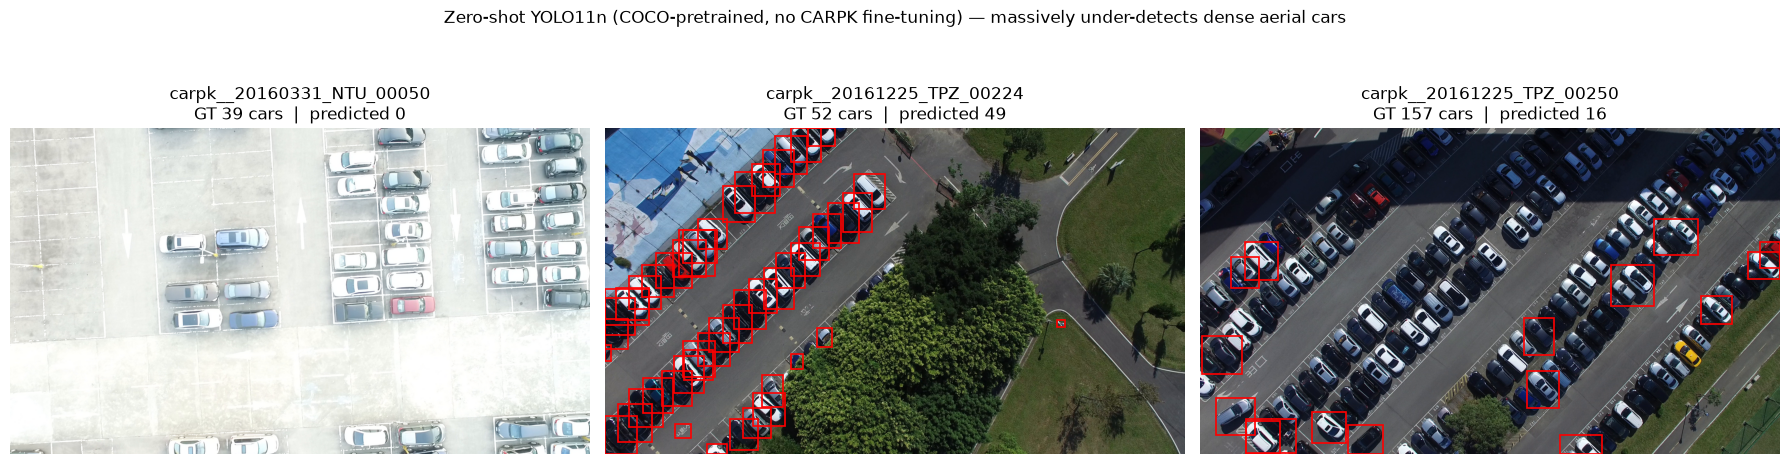

In [16]:
# --- Section 2.1: example zero-shot predictions (red = un-fine-tuned boxes) ---
baseline.plot_zeroshot_examples(model)

### 2.2 Typical detectors for dense small objects
- **YOLO family (v5 / v8 / YOLO11):** single-stage, real-time, clean single detection head;
  strong on small objects at high input resolution. Chosen here (YOLO11n) for speed.
- **Faster R-CNN:** two-stage, accurate but slower/heavier — the classic CARPK baseline.
- **RetinaNet / FCOS:** one-stage focal-loss / anchor-free heads with good small-object recall.

For hundreds of tiny, tightly packed cars, **input resolution** and **NMS behaviour** matter
more than backbone size — hence training at `imgsz=1280` with a small backbone.

### 2.3 Counting-by-detection vs density-map counting
- **Density-map counting** regresses a per-pixel density map whose integral is the count
  (e.g. MCNN, CSRNet). It excels at extreme crowding/occlusion but gives **no boxes**, so it
  cannot localize individual cars.
- **Counting-by-detection** detects each object and sets `count = #boxes`. It yields both
  **localization and count** in one pass, and is directly interpretable.

**Justification:** the project deliverable is an app that returns an **image with boxed cars
+ total count**. Localization is therefore mandatory, so counting-by-detection is the natural
choice; CARPK cars are large and separated enough for a detector to resolve them individually.

### 2.4 Typical training approach
- **Transfer learning:** start from COCO-pretrained weights and fine-tune on CARPK — far
  fewer epochs and better small-object features than training from scratch.
- **High input resolution** (`imgsz=1280`, native size) so small cars survive downsampling.
- **Augmentation:** mosaic, scale/translate jitter, HSV; **single class** `0 = car`.
- **Multi-GPU** data-parallel training (`device=[0,1]`) to halve wall-clock time.

---
## 3. Collected data & exploration  [3 pts]

### 3.0 Combining the datasets into one final dataset
Two complementary aerial car devkits ship with this project and share the **exact same**
on-disk layout and annotation format (`x1 y1 x2 y2 class`, absolute pixels, class `1 = car`,
native 1280x720):

- **CARPK** — 1448 drone images over 4 parking lots (`datasets/CARPK_devkit`),
- **PUCPR+** — 125 fixed-camera parking-lot images in varied weather (`datasets/PUCPR+_devkit`).

Because the formats are identical, we first **merge them into a single final dataset**
(`datasets/combined_devkit`) that the rest of the project treats as one source. Each image id
is namespaced with a `carpk__` / `pucpr__` prefix so the two origins never clash and stay
traceable, and the official train/test splits of both devkits are concatenated. The merge is
implemented in `src/1_phase/combine.py` and executed by the cell below.

All dataset statistics and exploration that follow are then computed directly from the files
on disk:
- number of images and cars, cars-per-image distribution (min / max / mean),
- bounding-box size and aspect-ratio distributions (the small-object challenge),
- the labeling format and the train / val / test partition plan.


In [17]:
# --- Section 3.0: combine CARPK + PUCPR+ into one final dataset on disk ---
import sys; sys.path.insert(0, "src/1_phase")
import combine

combined_summary = combine.combine_datasets()
combined_summary

Final combined devkit written to: datasets/combined_devkit/data
  train: 1089 images / 55270 cars
  test : 484 images / 51420 cars


,source,split,images,cars
0,carpk,train,989,42274
1,carpk,test,459,47500
2,pucpr,train,100,12996
3,pucpr,test,25,3920


In [18]:
# --- Section 3: load the exploration helpers and show the dataset paths ---
import importlib
import exploration; importlib.reload(exploration)
from config import IMAGES, ANN, SETS, IMG_W, IMG_H

print("Images dir :", IMAGES)
print("Annotations:", ANN)
print("ImageSets  :", SETS)

Images dir : datasets/combined_devkit/data/Images
Annotations: datasets/combined_devkit/data/Annotations
ImageSets  : datasets/combined_devkit/data/ImageSets


In [19]:
# --- Load and sanity-check the official train/test splits ---
train_ids, test_ids, all_ids = exploration.load_splits()

#images total : 1573
#train (official): 1089
#test  (official): 484
Splits are disjoint and cover every image.


In [20]:
# --- Confirm a sample image resolution ---
exploration.check_sample_resolution(all_ids)

Sample image: carpk__20160331_NTU_00001 size (1280, 720) mode RGB


(1280, 720)

In [21]:
# --- Parse every annotation file into a per-box table ---
boxes, per_image_counts, degenerate = exploration.parse_annotations(all_ids, train_ids)
boxes.head()

Skipped 55 degenerate boxes (zero width/height).
Total annotated cars: 106,635
Classes present: [np.int64(1)]


,img_id,split,x1,y1,x2,y2,cls,w,h,area,aspect
0,carpk__20160331_NTU_00001,train,1019,521,1129,571,1,110,50,5500,2.200000
1,carpk__20160331_NTU_00001,train,1013,583,1120,634,1,107,51,5457,2.098039
2,carpk__20160331_NTU_00001,train,1007,640,1112,693,1,105,53,5565,1.981132
3,carpk__20160331_NTU_00001,train,1006,694,1119,719,1,113,25,2825,4.520000
4,carpk__20160331_NTU_00002,train,1023,524,1131,570,1,108,46,4968,2.347826


**Degenerate boxes are dropped at dataset-build time.** A few PUCPR+ annotations are *degenerate* — `x1 == x2` or `y1 == y2`, i.e. zero width or height. They are not valid cars, cannot be normalised to a YOLO box, and would break aspect-ratio statistics (`w / h` divides by zero). The `combine` step (section 3.0) filters them out when it writes the combined devkit, so the dataset on disk is already clean. The cell below is a **verification**: it re-checks the parsed boxes and asserts none slipped through (Phase 2's `carpk_to_yolo` applies the same `w <= 0 or h <= 0` guard as a final safety net).

In [ ]:
# --- Verify the dataset is clean: no degenerate boxes should remain ---
print(f"Degenerate boxes still present after parsing: {len(degenerate)}")
assert len(degenerate) == 0, "degenerate boxes leaked into the combined devkit"
print("OK — combined devkit has no zero width/height boxes.")

In [22]:
# --- Cars-per-image distribution ---
exploration.cars_per_image_summary(per_image_counts, train_ids, test_ids)

,images,total_cars,min,max,mean,median,std
all,1573.0,106635.0,0.0,331.0,67.79,50.0,52.24
train,1089.0,55215.0,0.0,331.0,50.70,40.0,43.89
test,484.0,51420.0,1.0,328.0,106.24,112.0,49.04


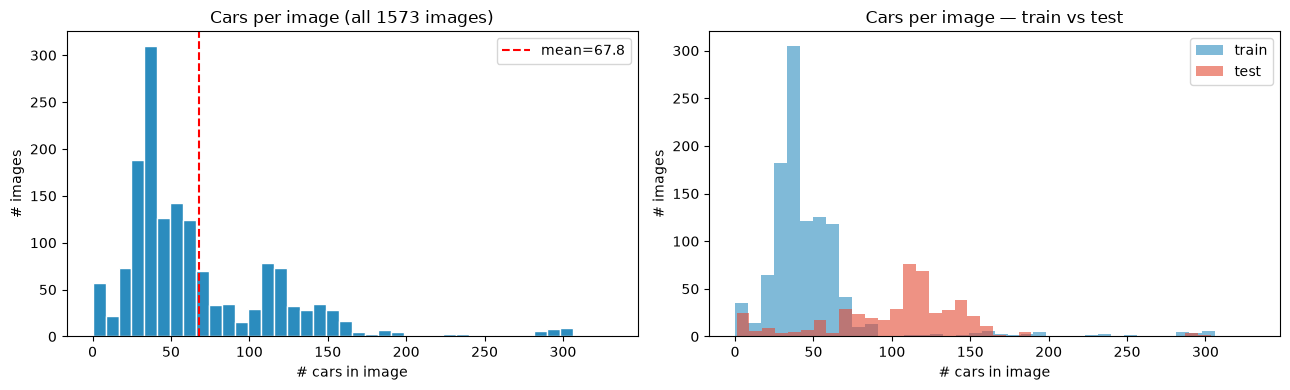

In [23]:
# --- Plot: cars-per-image distribution ---
exploration.plot_cars_per_image(per_image_counts, train_ids, test_ids)

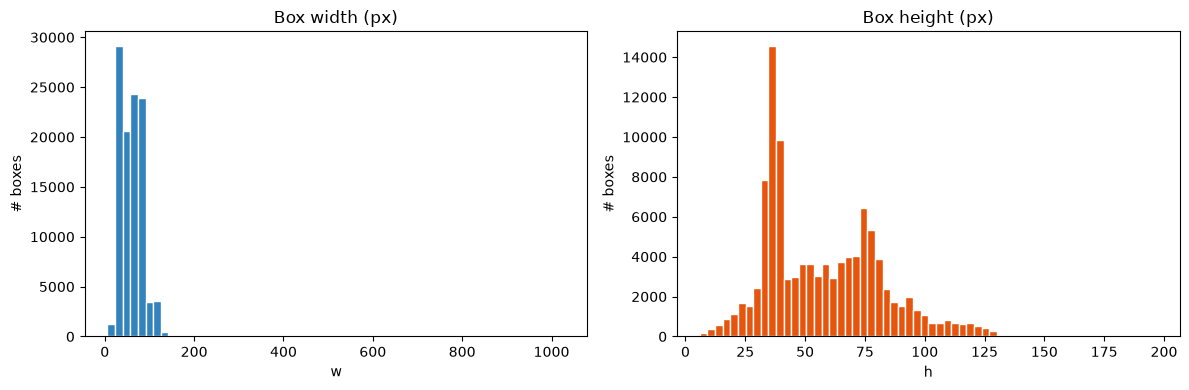

In [24]:
# --- Box width & height distributions (small-object challenge) ---
exploration.plot_box_wh(boxes)

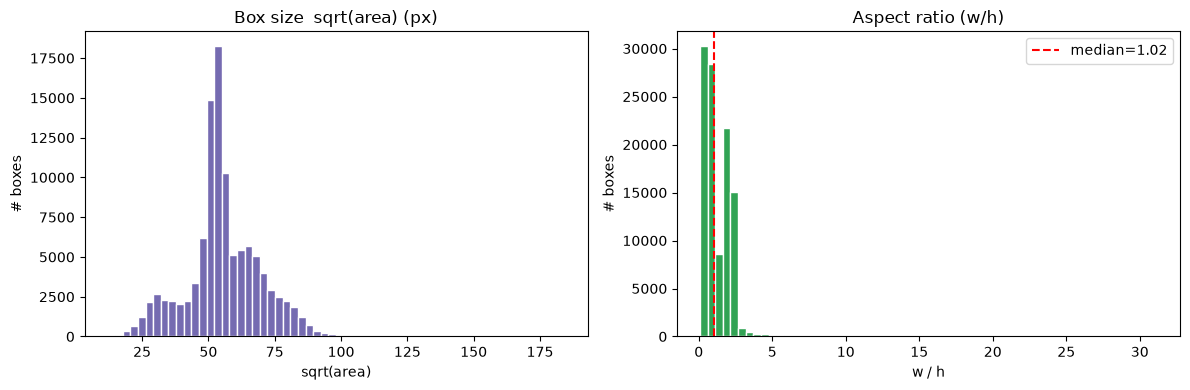

In [25]:
# --- Plot: box size and aspect-ratio distributions ---
exploration.plot_box_sizes(boxes)

The aspect-ratio axis stretches to ~14 only because of a few extreme outliers — cars clipped by the bottom edge of the image (height of just 6–7 px), so `w/h` blows up. These are very rare:

- Boxes with w/h > 3: **1,897 (2.1%)**
- w/h > 5: 562 (0.6%)
- w/h > 8: 83 (0.09%)
- w/h > 10: only **15 (0.017%)**

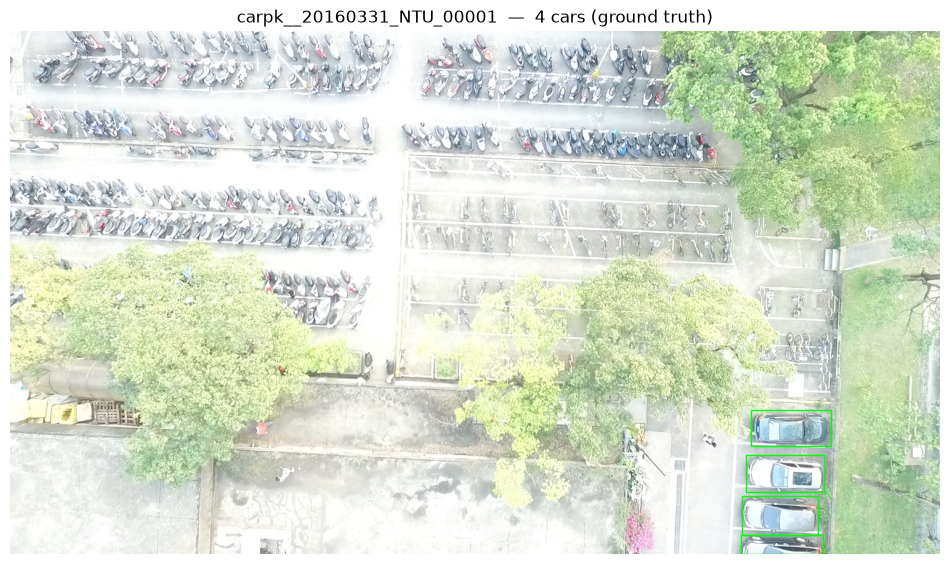

In [26]:
# --- Visualize a sample image with its ground-truth boxes ---
exploration.plot_sample_gt(boxes, train_ids)

### 3.1 Labeling format

**On-disk CARPK format** — one `.txt` per image in `Annotations/`, one line per car:

```
x1 y1 x2 y2 class
```

- `x1 y1` = top-left corner, `x2 y2` = bottom-right corner, **absolute pixels**;
- `class` = `1` (car) for every box (single-category dataset).

**Example:** `1019 521 1129 571 1` → a car box from (1019, 521) to (1129, 571).

**Target YOLO format** (conversion done in Phase 2) — normalized, single class `0 = car`:

$$c_x=\frac{x_1+x_2}{2W},\quad c_y=\frac{y_1+y_2}{2H},\quad
w=\frac{x_2-x_1}{W},\quad h=\frac{y_2-y_1}{H},$$

with $W=1280,\ H=720$, giving lines `0 cx cy w h` with all values in $[0,1]$.


In [27]:
# --- Demonstrate the CARPK -> YOLO conversion on one box (no files written) ---
exploration.conversion_demo(boxes)

CARPK : 1019 521 1129 571 1
YOLO  : 0 0.839063 0.758333 0.085938 0.069444
All normalized values are within [0, 1].


(np.float64(0.8390625),
 np.float64(0.7583333333333333),
 np.float64(0.0859375),
 np.float64(0.06944444444444445))

### 3.2 Train / val / test partition plan

| Split | Source | #images | Purpose |
|---|---|---|---|
| **train** | ~90% of official `train.txt` | ≈890 | fit model weights |
| **val**   | ~10% of official `train.txt` (random seed, held out) | ≈99 | model selection / early stopping |
| **test**  | official `test.txt` (untouched) | 459 | final MAE / RMSE / mAP benchmark |

- The **official 459-image test split is kept completely clean** — never seen during training
  or model selection — so results are comparable with published CARPK numbers.
- The **val set is carved only from the official training ids** (~10%), used for hyper-parameter
  choice and early stopping.
- Conversion to YOLO layout (`datasets/yolo/images/{train,val}` + `labels/{train,val}`) and the
  `carpk.yaml` config are produced in **Phase 2**.

The cell below shows the concrete, reproducible train/val split sizes.


In [28]:
# --- Concrete reproducible train/val carve from the official training ids ---
exploration.train_val_partition(train_ids, test_ids, per_image_counts)

,split,#images,#cars,source
0,train (fit),980,50118,official train (90%)
1,val,109,5097,official train (10%)
2,test,484,51420,official test (clean)


---
## 4. Phase 1 — summary of findings

- **Problem**: single-class (car) detection + localization + counting on aerial parking-lot
  images, with `count = #boxes after NMS` (counting-by-detection, single YOLO head).
- **Metrics**: **MAE** and **RMSE** of the count (CARPK standard) plus detection **mAP@0.5**.
- **Baselines**: LPN (MAE ≈ 23.8 / RMSE ≈ 36.8) is the historical reference; modern YOLO
  fine-tuning targets single-digit MAE.
- **Data**: 1448 images (989 train / 459 test), 1280×720, ~90k cars; cars are **small and
  dense** (see COCO size buckets and box-size plots above), which is exactly what makes the
  task challenging.
- **Plan**: keep the 459-image test split clean; carve ~10% of train for validation; convert
  to YOLO normalized format in Phase 2.

All Phase 1 checklist items (problem formulation, technical review, data statistics, box-size /
aspect-ratio analysis, labeling format and partition plan) are resolved above. The remaining
deliverable is the ~5-minute slide deck, which is built from the tables and figures produced here.
